# Controlled comparison overview

**Design stage: no new NF2 or matched-input NFPT comparison has been executed.** Archived diagnostics below are evidence for the existing manuscript only. Future scalar evaluations appear separately; common evaluation alone does not certify acquisition controls.

In [1]:
from pathlib import Path
import json, importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from nfgs.paths import project_root
ROOT = project_root()
config = json.loads((ROOT / 'configs/controlled_comparison.json').read_text())
spec = importlib.util.spec_from_file_location('planner', ROOT / 'scripts/plan_controlled_comparison.py')
planner = importlib.util.module_from_spec(spec); spec.loader.exec_module(planner)
manifest = planner.plan(config)
pd.Series({key: manifest[key] for key in ['status','primary_job_count','NF2_training_count']})

status                draft_design_not_execution_ready
primary_job_count                                  234
NF2_training_count                                 180
dtype: object

In [2]:
jobs = pd.DataFrame(manifest['jobs'])
display(jobs.groupby(['stage','method']).size().rename('Planned jobs').reset_index())
display(pd.Series(manifest['execution_gates'], name='Unresolved execution gates'))
# Training-time estimate follows a measured pilot, never an invented runtime.
print('TD NF2 cost = 165 × measured pilot hours; Low–Lou default adds 15 training runs.')

,stage,method,Planned jobs
0,E1,NFPT_Fortran,3
1,E1,NFPT_GPU,3
2,E1_E2,NFGS,33
3,E2,NF2,165
4,E3,NF2,15
5,E3,NFGS,9
6,E3,NFPT_Fortran,3
7,E3,NFPT_GPU,3


0    coordinate-explicit case bundles and P0 scalar...
1          NFPT source/executable license and settings
2    matched actual Fortran/GPU calculation coordin...
3    NF2 numpy x-y transpose and bottom-only datase...
4           NF2 pilot budget and training steps frozen
5       anisotropic FastQSL/potential/helicity support
6           funding and real Zenodo DOI for submission
Name: Unresolved execution gates, dtype: object

TD NF2 cost = 165 × measured pilot hours; Low–Lou default adds 15 training runs.


## Archived trade-off evidence

The archived NFPT inputs were resampled to native grids. These curves are **not** fresh matched-input ablations. No NF2 points are fabricated.

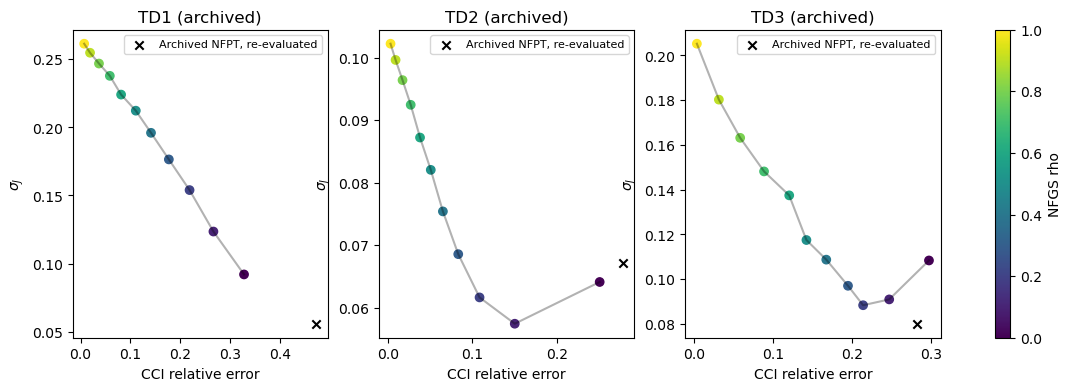

In [3]:
data = pd.read_csv(ROOT / 'reference_results/common_diagnostics/headline_common_fd2_protocol.csv')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, case in zip(axes, ['td1','td2','td3']):
    group = data[(data.benchmark == case) & data.method.str.startswith('nfgs_')].sort_values('rho')
    dots = ax.scatter(group.E_rel_Bgt_domain, group.sigma_J, c=group.rho, vmin=0, vmax=1, cmap='viridis')
    ax.plot(group.E_rel_Bgt_domain, group.sigma_J, color='black', alpha=.3)
    nfpt = data[(data.benchmark == case) & (data.method == 'nfpt_fortran_symmetric')]
    ax.scatter(nfpt.E_rel_Bgt_domain, nfpt.sigma_J, marker='x', color='black', label='Archived NFPT, re-evaluated')
    ax.set(title=case.upper()+' (archived)', xlabel='CCI relative error', ylabel=r'$\sigma_J$'); ax.legend(fontsize=8)
fig.colorbar(dots, ax=list(axes), label='NFGS rho'); plt.show()

## Fresh common-evaluator output

Run `evaluate.py` on coordinate-explicit case bundles. FastQSL, twist, six-face energy and helicity are separate implementation gates. A scalar result does not claim those diagnostics were computed.

In [4]:
fresh = []
for path in (ROOT / 'results/controlled').rglob('metrics.json'):
    item = json.loads(path.read_text())
    if item.get('current_operator') == 'common_fd2_float64_full_volume_then_crop':
        fresh.append({'case':item['case'], 'method':item['method'], 'path':str(path),
                      'acquisition_verified':item.get('controlled_acquisition_verified',False),
                      **{key:item['metrics'].get(key) for key in ['C_vec','sigma_J','E_rel_Bgt','E_rel_Bgt_L2']}})
if fresh:
    display(pd.DataFrame(fresh))
else:
    print('No new controlled-comparison scalar outputs are present.')

No new controlled-comparison scalar outputs are present.
